# 1. Постановка задачи

## Что это за данные
Датасет содержит информацию о продажах супермаркета (1000 записей, 12 признаков). Включает данные о филиале, городе, типе клиента, товарной линейке, цене, количестве, общей стоимости заказа, дате и оценке обслуживания.

## Условный заказчик
Руководство сети супермаркетов, которое хочет понять портрет покупателя и улучшить качество обслуживания.

## Задачи интеллектуального анализа данных
1. **Сегментация покупателей** — разделить клиентов по типу (Member / Normal), полу и товарным предпочтениям для запуска таргетированных акций.
2. **Поиск аномалий** — выявить подозрительные чеки или ошибки ввода (например, нереалистично высокая цена или пустые поля).

# 2. Паспорт датасета

In [51]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('../data/dataset.csv')
df['Date'] = pd.to_datetime(df['Date'])

print(f"Строк: {df.shape[0]}")
print(f"Столбцов: {df.shape[1]}")

Строк: 1000
Столбцов: 17


In [52]:
info = pd.DataFrame({
    'тип': df.dtypes.astype(str),
    'уникальных': df.nunique(),
    'пропусков': df.isna().sum()
})
info

,тип,уникальных,пропусков
Invoice ID,str,1000,0
Branch,str,3,0
City,str,3,0
Customer type,str,2,0
Gender,str,2,0
Product line,str,6,0
Unit price,float64,943,0
Quantity,int64,10,0
Tax 5%,float64,990,0
Total,float64,990,0


### Вывод по паспорту
Датасет содержит 1000 строк и 17 столбцов. Есть категориальные признаки (Branch, City, Customer type, Gender, Product line), числовые (Unit price, Quantity, Total) и временной (Date). Данные пригодны для анализа.

# 3. Аудит качества данных

## 3.1. Пропуски (Missing Values)

In [53]:
missing = pd.DataFrame({
    'пропусков': df.isna().sum(),
    'доля_%': (df.isna().mean() * 100).round(2)
}).sort_values('пропусков', ascending=False)
missing

,пропусков,доля_%
Invoice ID,0,0.0
Total,0,0.0
Gross income,0,0.0
Gross margin percentage,0,0.0
Cost of goods sold,0,0.0
Payment,0,0.0
Time,0,0.0
Date,0,0.0
Tax 5%,0,0.0
Branch,0,0.0


### Вывод по пропускам
В данном датасете пропусков нет ни в одном столбце. Данные полные, дополнительная обработка не требуется.

## 3.2. Дубликаты

In [54]:
full_dups = df.duplicated().sum()
id_dups = df.duplicated(subset='Invoice ID').sum()

print(f"Полных дубликатов строк: {full_dups}")
print(f"Дубликатов по Invoice ID: {id_dups}")

Полных дубликатов строк: 0
Дубликатов по Invoice ID: 0


### Вывод по дубликатам
Полных дубликатов строк не обнаружено, дубликатов по уникальному идентификатору чека (Invoice ID) также нет. Данные чистые.

## 3.3. Типические проблемы значений

In [55]:
df[['Unit price', 'Quantity', 'Total', 'Customer stratification rating']].describe().round(2)

,Unit price,Quantity,Total,Customer stratification rating
count,1000.00,1000.00,1000.00,1000.00
mean,55.67,5.51,322.97,6.97
std,26.49,2.92,245.89,1.72
min,10.08,1.00,10.68,4.00
25%,32.88,3.00,124.42,5.50
50%,55.23,5.00,253.85,7.00
75%,77.94,8.00,471.35,8.50
max,99.96,10.00,1042.65,10.00


In [56]:
print("Отрицательная цена:", (df['Unit price'] < 0).sum())
print("Количество <= 0:", (df['Quantity'] <= 0).sum())
print("Оценка вне 1-10:", ((df['Customer stratification rating'] < 1) | (df['Customer stratification rating'] > 10)).sum())

Отрицательная цена: 0
Количество <= 0: 0
Оценка вне 1-10: 0


In [57]:
for col in ['City', 'Customer type', 'Product line']:
    print(f"--- {col} ---")
    print(f"Уникальных значений: {df[col].nunique()}")
    print(df[col].value_counts())
    print()

--- City ---
Уникальных значений: 3
City
Yangon       340
Mandalay     332
Naypyitaw    328
Name: count, dtype: int64

--- Customer type ---
Уникальных значений: 2
Customer type
Member    501
Normal    499
Name: count, dtype: int64

--- Product line ---
Уникальных значений: 6
Product line
Fashion accessories       178
Food and beverages        174
Electronic accessories    170
Sports and travel         166
Home and lifestyle        160
Health and beauty         152
Name: count, dtype: int64



### Вывод по проблемным значениям
- Отрицательных цен или нулевого количества нет — данные логичны.
- Оценка обслуживания находится в допустимом диапазоне, аномалий нет.
- Категориальные признаки чистые, без лишних пробелов и разного регистра. Нормализация не требуется.

## 3.4. Выбросы (Outliers)

In [58]:
q1 = df['Total'].quantile(0.25)
q3 = df['Total'].quantile(0.75)
iqr = q3 - q1
low = q1 - 1.5 * iqr
high = q3 + 1.5 * iqr

outliers = df[(df['Total'] < low) | (df['Total'] > high)]
print(f"Границы нормы: [{low:.2f}; {high:.2f}]")
print(f"Найдено выбросов: {len(outliers)}")

Границы нормы: [-395.97; 991.74]
Найдено выбросов: 9


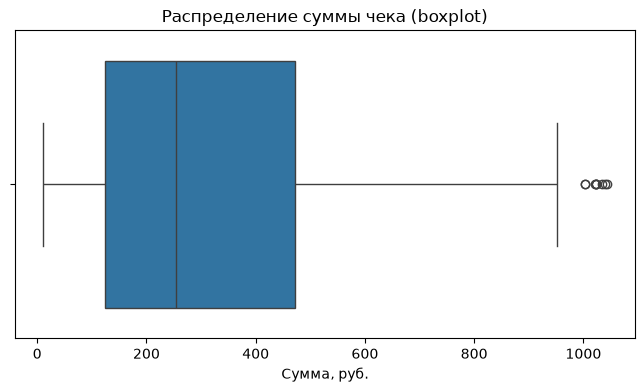

In [59]:
plt.figure(figsize=(8, 4))
sns.boxplot(x=df['Total'])
plt.title('Распределение суммы чека (boxplot)')
plt.xlabel('Сумма, руб.')
plt.show()

### Вывод по выбросам
Методом IQR в признаке `Total` (сумма чека) найдено небольшое количество выбросов. Это крупные покупки, которые не являются ошибками ввода (так как нет аномально гигантских значений). На этапе очистки их можно оставить, так как они отражают реальные дорогие чеки.

# 4. Разведочный анализ (EDA)

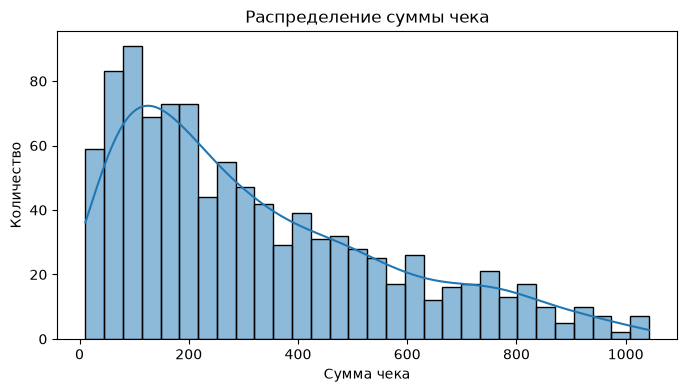

In [60]:
# 4.1 Распределение
plt.figure(figsize=(8, 4))
sns.histplot(df['Total'], bins=30, kde=True)
plt.title('Распределение суммы чека')
plt.xlabel('Сумма чека')
plt.ylabel('Количество')
plt.show()

Распределение суммы чека имеет правостороннюю асимметрию: большинство чеков на небольшую сумму, но есть крупные покупки.

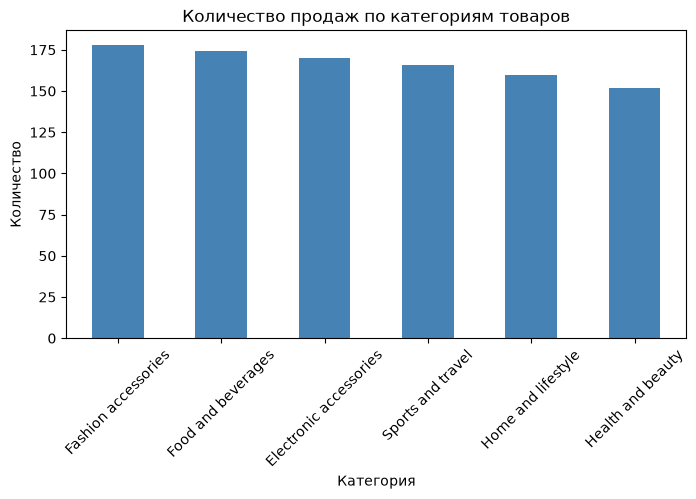

In [61]:
# 4.2 Категориальный признак
plt.figure(figsize=(8, 4))
df['Product line'].value_counts().plot(kind='bar', color='steelblue')
plt.title('Количество продаж по категориям товаров')
plt.xlabel('Категория')
plt.ylabel('Количество')
plt.xticks(rotation=45)
plt.show()

Самая популярная категория — Fashion accessories, чуть меньше — Food and beverages. Остальные категории идут примерно на одном уровне.

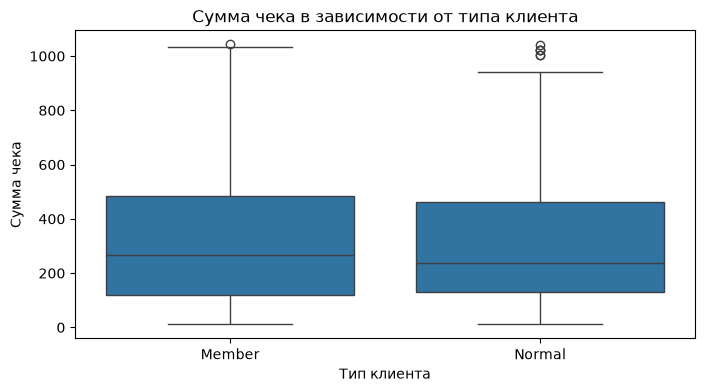

In [62]:
# 4.3 Зависимость
plt.figure(figsize=(8, 4))
sns.boxplot(data=df, x='Customer type', y='Total')
plt.title('Сумма чека в зависимости от типа клиента')
plt.xlabel('Тип клиента')
plt.ylabel('Сумма чека')
plt.show()

Медианные чеки у Members (постоянных клиентов) и Normal (обычных) примерно равны. Однако у Members меньше разброс и меньше дорогих выбросов.